# Supplementary Material - Figure 1 - Analysis Code

In [1]:
import os
import numpy as np
import pandas as pd
import pickle
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from sklearn.preprocessing import StandardScaler

In [2]:
DATA_PATH = "../../cnt-data/"
TABLES_PATH = os.path.join(DATA_PATH, "revised_tables_step_4")

sns.set_style("whitegrid")

In [3]:
def get_patient_hup_ids(directory):
    # List all files in the directory
    files = os.listdir(directory)

    # Filter out files based on the given pattern and extract patient_hup_id as integers
    patient_hup_ids = [
        int(f.split("_")[1].split(".")[0]) for f in files if f.startswith("HUP_")
    ]

    return patient_hup_ids

In [4]:
completed_hup_ids = get_patient_hup_ids(TABLES_PATH)
completed_hup_ids.sort()
len(completed_hup_ids)

68

In [ ]:
# Load in os.path.join(DATA_PATH, HUP_SOZ.csv) file
soz_df = pd.read_csv(os.path.join(DATA_PATH, "HUP_SOZ.csv"))

# Select only rows where SOZ == "mesial temporal"
# Note: It is good practice to use .copy() to avoid SettingWithCopyWarning later
mtle_df = soz_df[soz_df["SOZ"] == "mesial temporal"].copy()

# pt_id column is HUP{pt_id}, extract only the integer part
mtle_df['pt_id'] = mtle_df['pt_id'].str.replace('HUP', '').astype(int)

# Assign the unique list of pt_ids to a variable
mtle_patient_ids = mtle_df['pt_id'].unique().tolist()
mtle_patient_ids.sort()

[126,
 127,
 133,
 135,
 138,
 140,
 141,
 142,
 162,
 163,
 164,
 165,
 181,
 185,
 187,
 190,
 191,
 192,
 199,
 202,
 204,
 205,
 218,
 219,
 221,
 223,
 224]

In [7]:
len(mtle_patient_ids)

27

In [8]:
# Filter completed_hup_ids to include only those in mtle_patient_ids
mtle_completed_hup_ids = [pt_id for pt_id in completed_hup_ids if pt_id in mtle_patient_ids]
mtle_completed_hup_ids.sort()
mtle_completed_hup_ids

[138,
 140,
 141,
 142,
 162,
 163,
 164,
 165,
 181,
 185,
 187,
 190,
 191,
 192,
 199,
 202,
 204,
 205,
 219,
 221,
 223]

In [9]:
len(mtle_completed_hup_ids)

21

In [10]:
dfs = []
for patient_hup_id in mtle_completed_hup_ids:
    patient_features_df = pd.read_csv(
        os.path.join(TABLES_PATH, f"HUP_{patient_hup_id}.csv"),
        low_memory=False
    )

    # Columns to keep (including spike_rate and patient_hup_id)
    columns_to_keep = [
        "emu_minute",
        "synchrony_broadband",
        "med_sum_no_lorazepam_raw",
        "time_since_last_seizure",
        "time_until_next_seizure",
        "ad_ratio",
        "tod_sin",
        "tod_cos",
        "tod_sin2",
        "tod_cos2",
        "spike_rate",
        "patient_hup_id",  # will add below but include for clarity
    ]

    # Add patient id
    patient_features_df["patient_hup_id"] = patient_hup_id

    # Robustly keep only existing columns (in case some are missing for a subject)
    existing_columns = [c for c in columns_to_keep if c in patient_features_df.columns]
    patient_features_df = patient_features_df[existing_columns]

    dfs.append(patient_features_df)

In [11]:
# Combine all patients
all_data = pd.concat(dfs).reset_index(drop=True)

In [12]:
model_vars = [
    "med_sum_no_lorazepam_raw",
    "synchrony_broadband",
    "time_since_last_seizure",
    "time_until_next_seizure",
    "emu_minute",
    "ad_ratio",
    "tod_sin",
    "tod_cos",
    "tod_sin2",
    "tod_cos2",
    "spike_rate",
    "patient_hup_id",  # group variable for the mixed model
]

# Keep rows complete on the variables involved in the mixed model
all_data = all_data.dropna(subset=model_vars).reset_index(drop=True)
print(f"Total rows after dropna on model variables: {len(all_data)}")

Total rows after dropna on model variables: 6849


In [13]:
scaler = StandardScaler()
cols_to_scale = [
    "synchrony_broadband",
    "time_since_last_seizure",
    "time_until_next_seizure",
    "emu_minute",
    "ad_ratio",
    "spike_rate",
]

# (tod_* are already bounded / periodic, so we leave them as-is)
all_data[cols_to_scale] = scaler.fit_transform(all_data[cols_to_scale])

## Figure 4 (A)

In [14]:
model_formula = (
    "med_sum_no_lorazepam_raw ~ "
    "synchrony_broadband + "
    "time_since_last_seizure + "
    "time_until_next_seizure + "
    "emu_minute + "
    "ad_ratio + "
    "tod_sin + tod_cos + tod_sin2 + tod_cos2 + "
    "spike_rate"
)

base_model = smf.mixedlm(
    model_formula,
    all_data,
    groups=all_data["patient_hup_id"],
)
base_result = base_model.fit()

print("\n--- Mixed Model Results (model-based SEs; for reference only) ---")
print(base_result.summary())

# Get fixed effect names (excluding variance components)
fixed_effects = list(base_result.fe_params.index)
print("\nFixed effects in the model:", fixed_effects)


--- Mixed Model Results (model-based SEs; for reference only) ---
                Mixed Linear Model Regression Results
Model:            MixedLM Dependent Variable: med_sum_no_lorazepam_raw
No. Observations: 6849    Method:             REML                    
No. Groups:       21      Scale:              0.5764                  
Min. group size:  22      Log-Likelihood:     -7935.9927              
Max. group size:  981     Converged:          Yes                     
Mean group size:  326.1                                               
----------------------------------------------------------------------
                           Coef.  Std.Err.    z    P>|z| [0.025 0.975]
----------------------------------------------------------------------
Intercept                   1.827    0.459   3.978 0.000  0.927  2.728
synchrony_broadband        -1.038    0.063 -16.357 0.000 -1.162 -0.913
time_since_last_seizure    -0.222    0.016 -14.167 0.000 -0.252 -0.191
time_until_next_seizure    

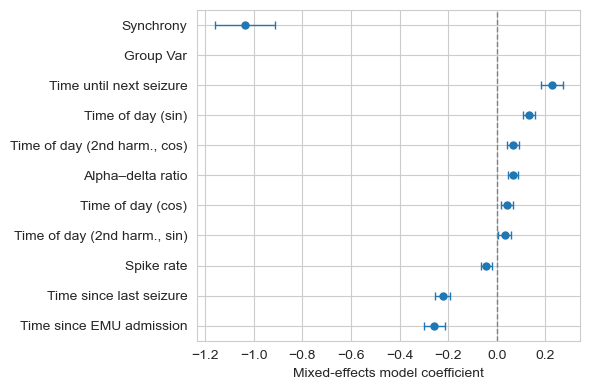

In [15]:
fe_params = base_result.fe_params          # fixed-effect estimates
conf_int = base_result.conf_int(alpha=0.05)  # 95% Wald CIs
conf_int.columns = ["ci_lower", "ci_upper"]

coefs = (
    pd.concat([fe_params, conf_int], axis=1)
    .reset_index()
    .rename(columns={"index": "term", 0: "estimate"})
)

# Drop intercept – usually not shown in coefficient plots
coefs = coefs[coefs["term"] != "Intercept"].copy()

# Optional: restrict to a subset of predictors (e.g., those you discuss in the text)
# keep_terms = [
#     "synchrony_broadband",
#     "time_since_last_seizure",
#     "emu_minute",
#     "ad_ratio",
#     "spike_rate"
# ]
# coefs = coefs[coefs["term"].isin(keep_terms)].copy()

# Nice labels for the manuscript (edit as you like)
label_map = {
    "synchrony_broadband":   "Synchrony",
    "time_since_last_seizure": "Time since last seizure",
    "time_until_next_seizure": "Time until next seizure",
    "emu_minute":             "Time since EMU admission",
    "ad_ratio":               "Alpha–delta ratio",
    "tod_sin":                "Time of day (sin)",
    "tod_cos":                "Time of day (cos)",
    "tod_sin2":               "Time of day (2nd harm., sin)",
    "tod_cos2":               "Time of day (2nd harm., cos)",
    "spike_rate":             "Spike rate"
}

coefs["label"] = coefs["term"].map(label_map).fillna(coefs["term"])

# ---------------------------------------------
# Sort logic
# ---------------------------------------------
# Create a helper column to force Synchrony to the top (True sorts after False)
coefs["is_synchrony"] = coefs["term"] == "synchrony_broadband"

# Sort first by whether it is synchrony (False then True), then by estimate size
coefs = coefs.sort_values(["is_synchrony", "estimate"])
# ---------------------------------------------

# Error bar extents
coefs["err_lower"] = coefs["estimate"] - coefs["ci_lower"]
coefs["err_upper"] = coefs["ci_upper"] - coefs["estimate"]

# ---------------------------------------------
# Plot: horizontal coefficient forest plot
# ---------------------------------------------
fig, ax = plt.subplots(figsize=(6, 4))  # adjust size for journal requirements

ax.errorbar(
    x=coefs["estimate"],
    y=coefs["label"],
    xerr=[coefs["err_lower"], coefs["err_upper"]],
    fmt="o",
    capsize=3,
    markersize=5,
    linewidth=1,
)

# Vertical line at 0 (no effect)
ax.axvline(0, color="gray", linestyle="--", linewidth=1)

# Axis labels – adjust wording depending on whether predictors were standardized
ax.set_xlabel("Mixed-effects model coefficient")
ax.set_ylabel("")

# Make layout clean for export
plt.tight_layout()
plt.show()

## Figure 4 (B)

In [15]:
n_boots = 5000 
rng = np.random.default_rng(seed=42) 

patient_ids = all_data["patient_hup_id"].unique()
n_patients = len(patient_ids)
print(f"\nBootstrapping with patient-level resampling over {n_patients} patients")

# Store coefficients for each fixed effect
boot_coefs = {name: [] for name in fixed_effects}

n_fail = 0

print("Starting bootstrap loop...")

for b in range(n_boots):
    if b % 100 == 0:
        print(f"Iteration {b}/{n_boots}...")

    # 1) Resample patients with replacement
    sampled_ids = rng.choice(patient_ids, size=n_patients, replace=True)

    # 2) Build bootstrap dataset by concatenating all rows from each sampled patient
    boot_dfs = [all_data[all_data["patient_hup_id"] == pid] for pid in sampled_ids]
    boot_data = pd.concat(boot_dfs, axis=0)

    # 3) Fit mixed model on bootstrap sample
    try:
        boot_model = smf.mixedlm(
            model_formula,
            boot_data,
            groups=boot_data["patient_hup_id"],
        )
        boot_result = boot_model.fit()

        # 4) Store fixed effect coefficients
        for name in fixed_effects:
            boot_coefs[name].append(boot_result.fe_params[name])

    except Exception as e:
        # If a particular bootstrap sample fails to converge, skip it
        n_fail += 1
        continue

print(f"\nBootstrap completed. Failed fits: {n_fail} out of {n_boots}")

# -------------------------------------------------------------------
# Summarize bootstrap distributions (median + CI)
# -------------------------------------------------------------------

summary_rows = []

for name in fixed_effects:
    coefs = np.array(boot_coefs[name])
    if len(coefs) == 0:
        # In case something went very wrong for this parameter
        summary_rows.append({
            "term": name,
            "median": np.nan,
            "ci95_lower": np.nan,
            "ci95_upper": np.nan,
            "ci99_lower": np.nan,
            "ci99_upper": np.nan,
            "n_boots_used": 0,
        })
        continue

    median = np.percentile(coefs, 50)
    ci95_lower, ci95_upper = np.percentile(coefs, [2.5, 97.5])
    ci99_lower, ci99_upper = np.percentile(coefs, [0.5, 99.5])

    summary_rows.append({
        "term": name,
        "median": median,
        "ci95_lower": ci95_lower,
        "ci95_upper": ci95_upper,
        "ci99_lower": ci99_lower,
        "ci99_upper": ci99_upper,
        "n_boots_used": len(coefs),
    })

bootstrap_summary = pd.DataFrame(summary_rows)
print("\n--- Bootstrap (patient-level) summary of fixed effects ---")
print(bootstrap_summary.to_string(index=False))

# Explicitly highlight synchrony_broadband
sync_row = bootstrap_summary[bootstrap_summary["term"] == "synchrony_broadband"]
if not sync_row.empty:
    r = sync_row.iloc[0]
    print("\nSynchrony (synchrony_broadband) bootstrap CI:")
    print(f"  median: {r['median']:.4f}")
    print(f"  95% CI: [{r['ci95_lower']:.4f}, {r['ci95_upper']:.4f}]")
    print(f"  99% CI: [{r['ci99_lower']:.4f}, {r['ci99_upper']:.4f}]")

# -------------------------------------------------------------------
# SAVE OUTPUT TO FILE
# -------------------------------------------------------------------
output_filename = "bootstrap_results_mtle.pkl"
print(f"\nSaving analysis results to {output_filename}...")

results_pack = {
    "boot_coefs": boot_coefs,
    "bootstrap_summary": bootstrap_summary,
    "n_boots": n_boots,
    "n_fail": n_fail
}

with open(output_filename, "wb") as f:
    pickle.dump(results_pack, f)

print("Save complete.")


Bootstrapping with patient-level resampling over 21 patients
Starting bootstrap loop...
Iteration 0/5000...
Iteration 100/5000...
Iteration 200/5000...
Iteration 300/5000...
Iteration 400/5000...
Iteration 500/5000...
Iteration 600/5000...
Iteration 700/5000...
Iteration 800/5000...
Iteration 900/5000...
Iteration 1000/5000...
Iteration 1100/5000...
Iteration 1200/5000...
Iteration 1300/5000...
Iteration 1400/5000...
Iteration 1500/5000...
Iteration 1600/5000...
Iteration 1700/5000...
Iteration 1800/5000...
Iteration 1900/5000...
Iteration 2000/5000...
Iteration 2100/5000...
Iteration 2200/5000...
Iteration 2300/5000...
Iteration 2400/5000...
Iteration 2500/5000...
Iteration 2600/5000...
Iteration 2700/5000...
Iteration 2800/5000...
Iteration 2900/5000...
Iteration 3000/5000...
Iteration 3100/5000...
Iteration 3200/5000...
Iteration 3300/5000...
Iteration 3400/5000...
Iteration 3500/5000...
Iteration 3600/5000...
Iteration 3700/5000...
Iteration 3800/5000...
Iteration 3900/5000...
Ite

In [16]:
input_filename = "bootstrap_results_mtle.pkl"

if not os.path.exists(input_filename):
    raise FileNotFoundError(f"Could not find '{input_filename}'. Please run the analysis script first.")

print(f"Loading results from {input_filename}...")
with open(input_filename, "rb") as f:
    saved_data = pickle.load(f)

# Extract the variables we need
boot_coefs = saved_data["boot_coefs"]
bootstrap_summary = saved_data["bootstrap_summary"]

print("Data loaded successfully.")

Loading results from bootstrap_results_mtle.pkl...
Data loaded successfully.


In [ ]:
boot_coefs

In [ ]:
bootstrap_summary

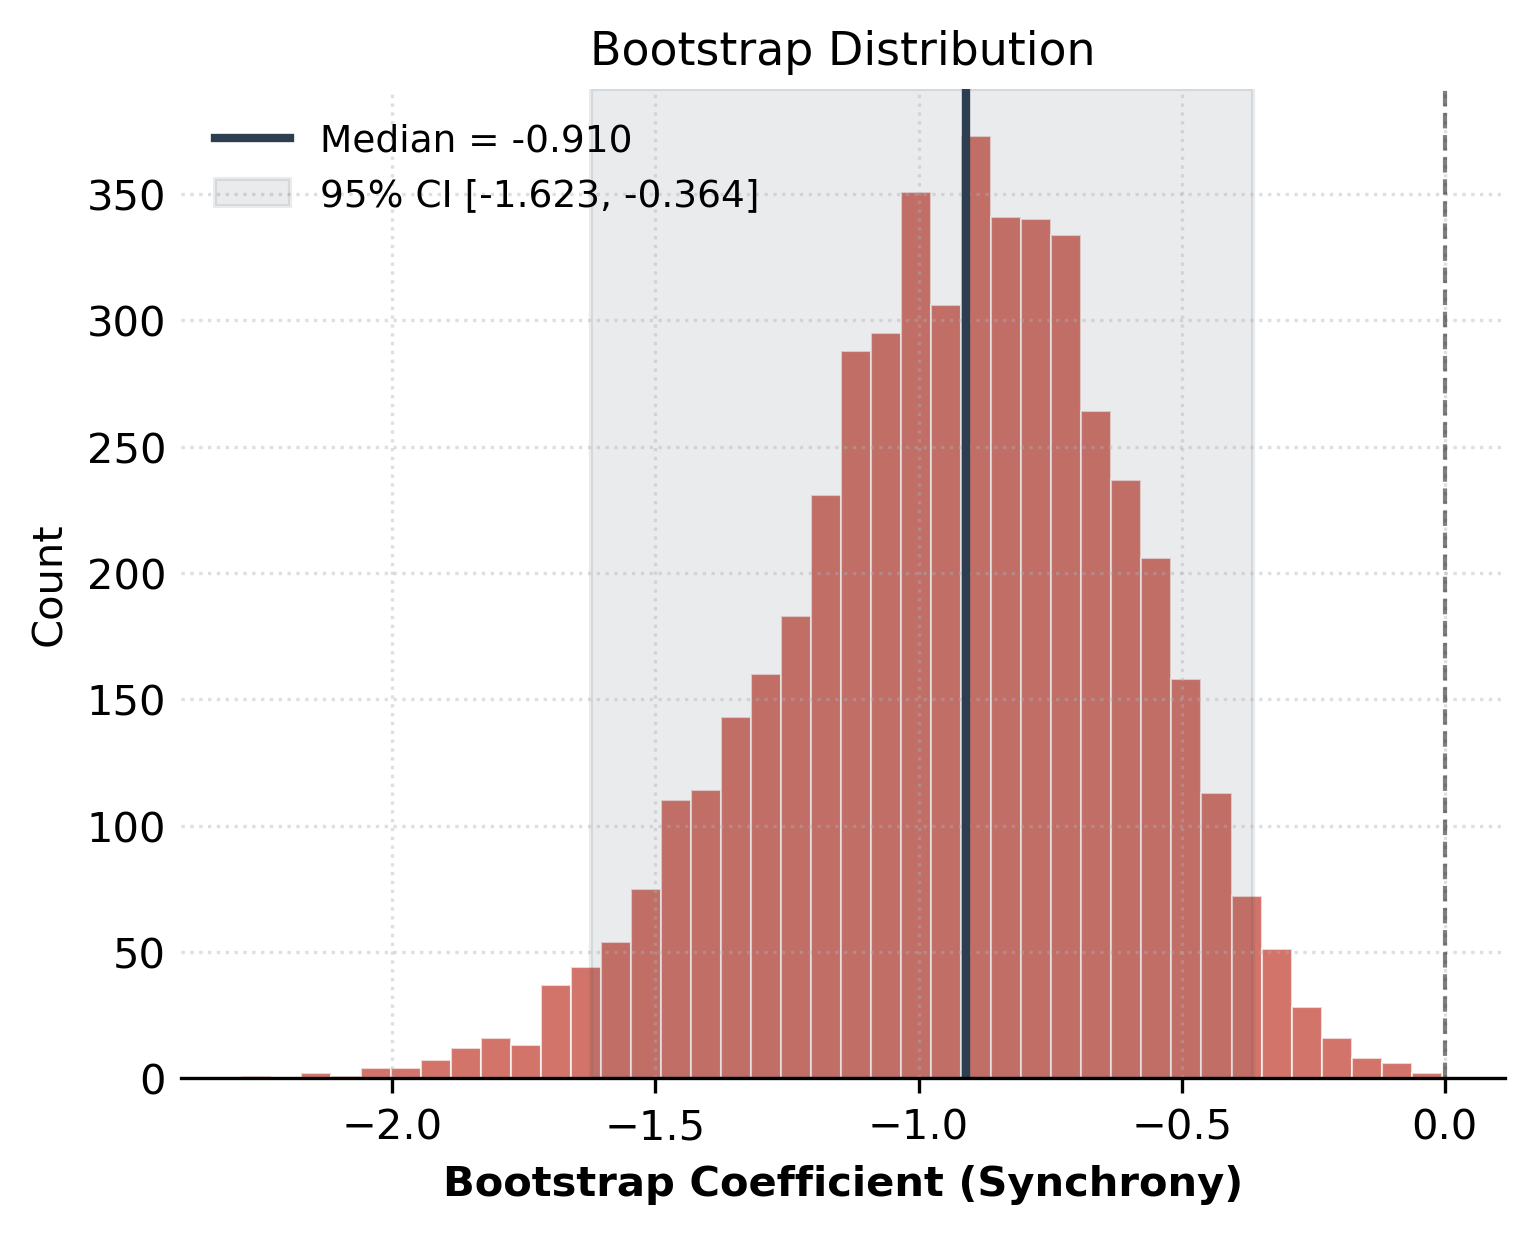

In [17]:
# --- Configuration based on Reference Style ---
STYLE_HIGHLIGHT = '#c0392b'  # Red (used for synchrony in reference)
STYLE_MAIN = '#2c3e50'       # Dark Slate (used for standard elements)
STYLE_GRID = {'linestyle': ':', 'alpha': 0.4}

sync_term = "synchrony_broadband"

if sync_term in boot_coefs:
    sync_coefs = np.array(boot_coefs[sync_term])
    
    # Calculate stats locally
    sync_median = np.median(sync_coefs)
    sync_ci95 = np.percentile(sync_coefs, [2.5, 97.5])

    # Use default to reset, then apply custom styling
    plt.style.use("default")

    fig, ax_hist = plt.subplots(
        figsize=(5, 4), dpi=300, constrained_layout=True
    )

    # 1. Histogram
    # Using the highlight red color from the reference since this is the synchrony term
    ax_hist.hist(sync_coefs, bins=40, color=STYLE_HIGHLIGHT, 
                 edgecolor='white', linewidth=0.5, alpha=0.7)

    # 2. Zero Line 
    # Matched styling: black, dashed, alpha=0.5
    ax_hist.axvline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)

    # 3. Median Line and CI
    # Using the darker slate color for specific stats to contrast nicely with the red bars
    ax_hist.axvline(sync_median, color=STYLE_MAIN, linestyle="-", linewidth=2,
                    label=f"Median = {sync_median:.3f}")
    
    ax_hist.axvspan(sync_ci95[0], sync_ci95[1], color=STYLE_MAIN, alpha=0.1,
                    label=f"95% CI [{sync_ci95[0]:.3f}, {sync_ci95[1]:.3f}]")

    # --- Styling ---
    # Bold label to match reference
    ax_hist.set_xlabel("Bootstrap Coefficient (Synchrony)", 
                       fontsize=10, fontweight='bold')
    ax_hist.set_ylabel("Count", fontsize=10)
    
    # Clean Title
    ax_hist.set_title("Bootstrap Distribution", fontsize=11)
    
    # Remove Spines (Top/Right/Left) to match reference 'clean' look
    ax_hist.spines['top'].set_visible(False)
    ax_hist.spines['right'].set_visible(False)
    ax_hist.spines['left'].set_visible(False) # Optional: keeping y-ticks but removing line
    
    # Add Grid (Reference used x-axis grid, but for histogram y-axis grid makes sense for counts)
    # We also add a light x-axis grid to help read the coefficient values
    ax_hist.grid(axis='y', **STYLE_GRID)
    ax_hist.grid(axis='x', **STYLE_GRID)
    
    # Ensure ticks are visible even if spines are gone
    ax_hist.tick_params(axis='y', length=0) 
    
    ax_hist.legend(frameon=False, fontsize=9, loc='upper left')

    plt.show()
else:
    print(f"Warning: '{sync_term}' not found in bootstrap coefficients.")

## Figure 4 (C)

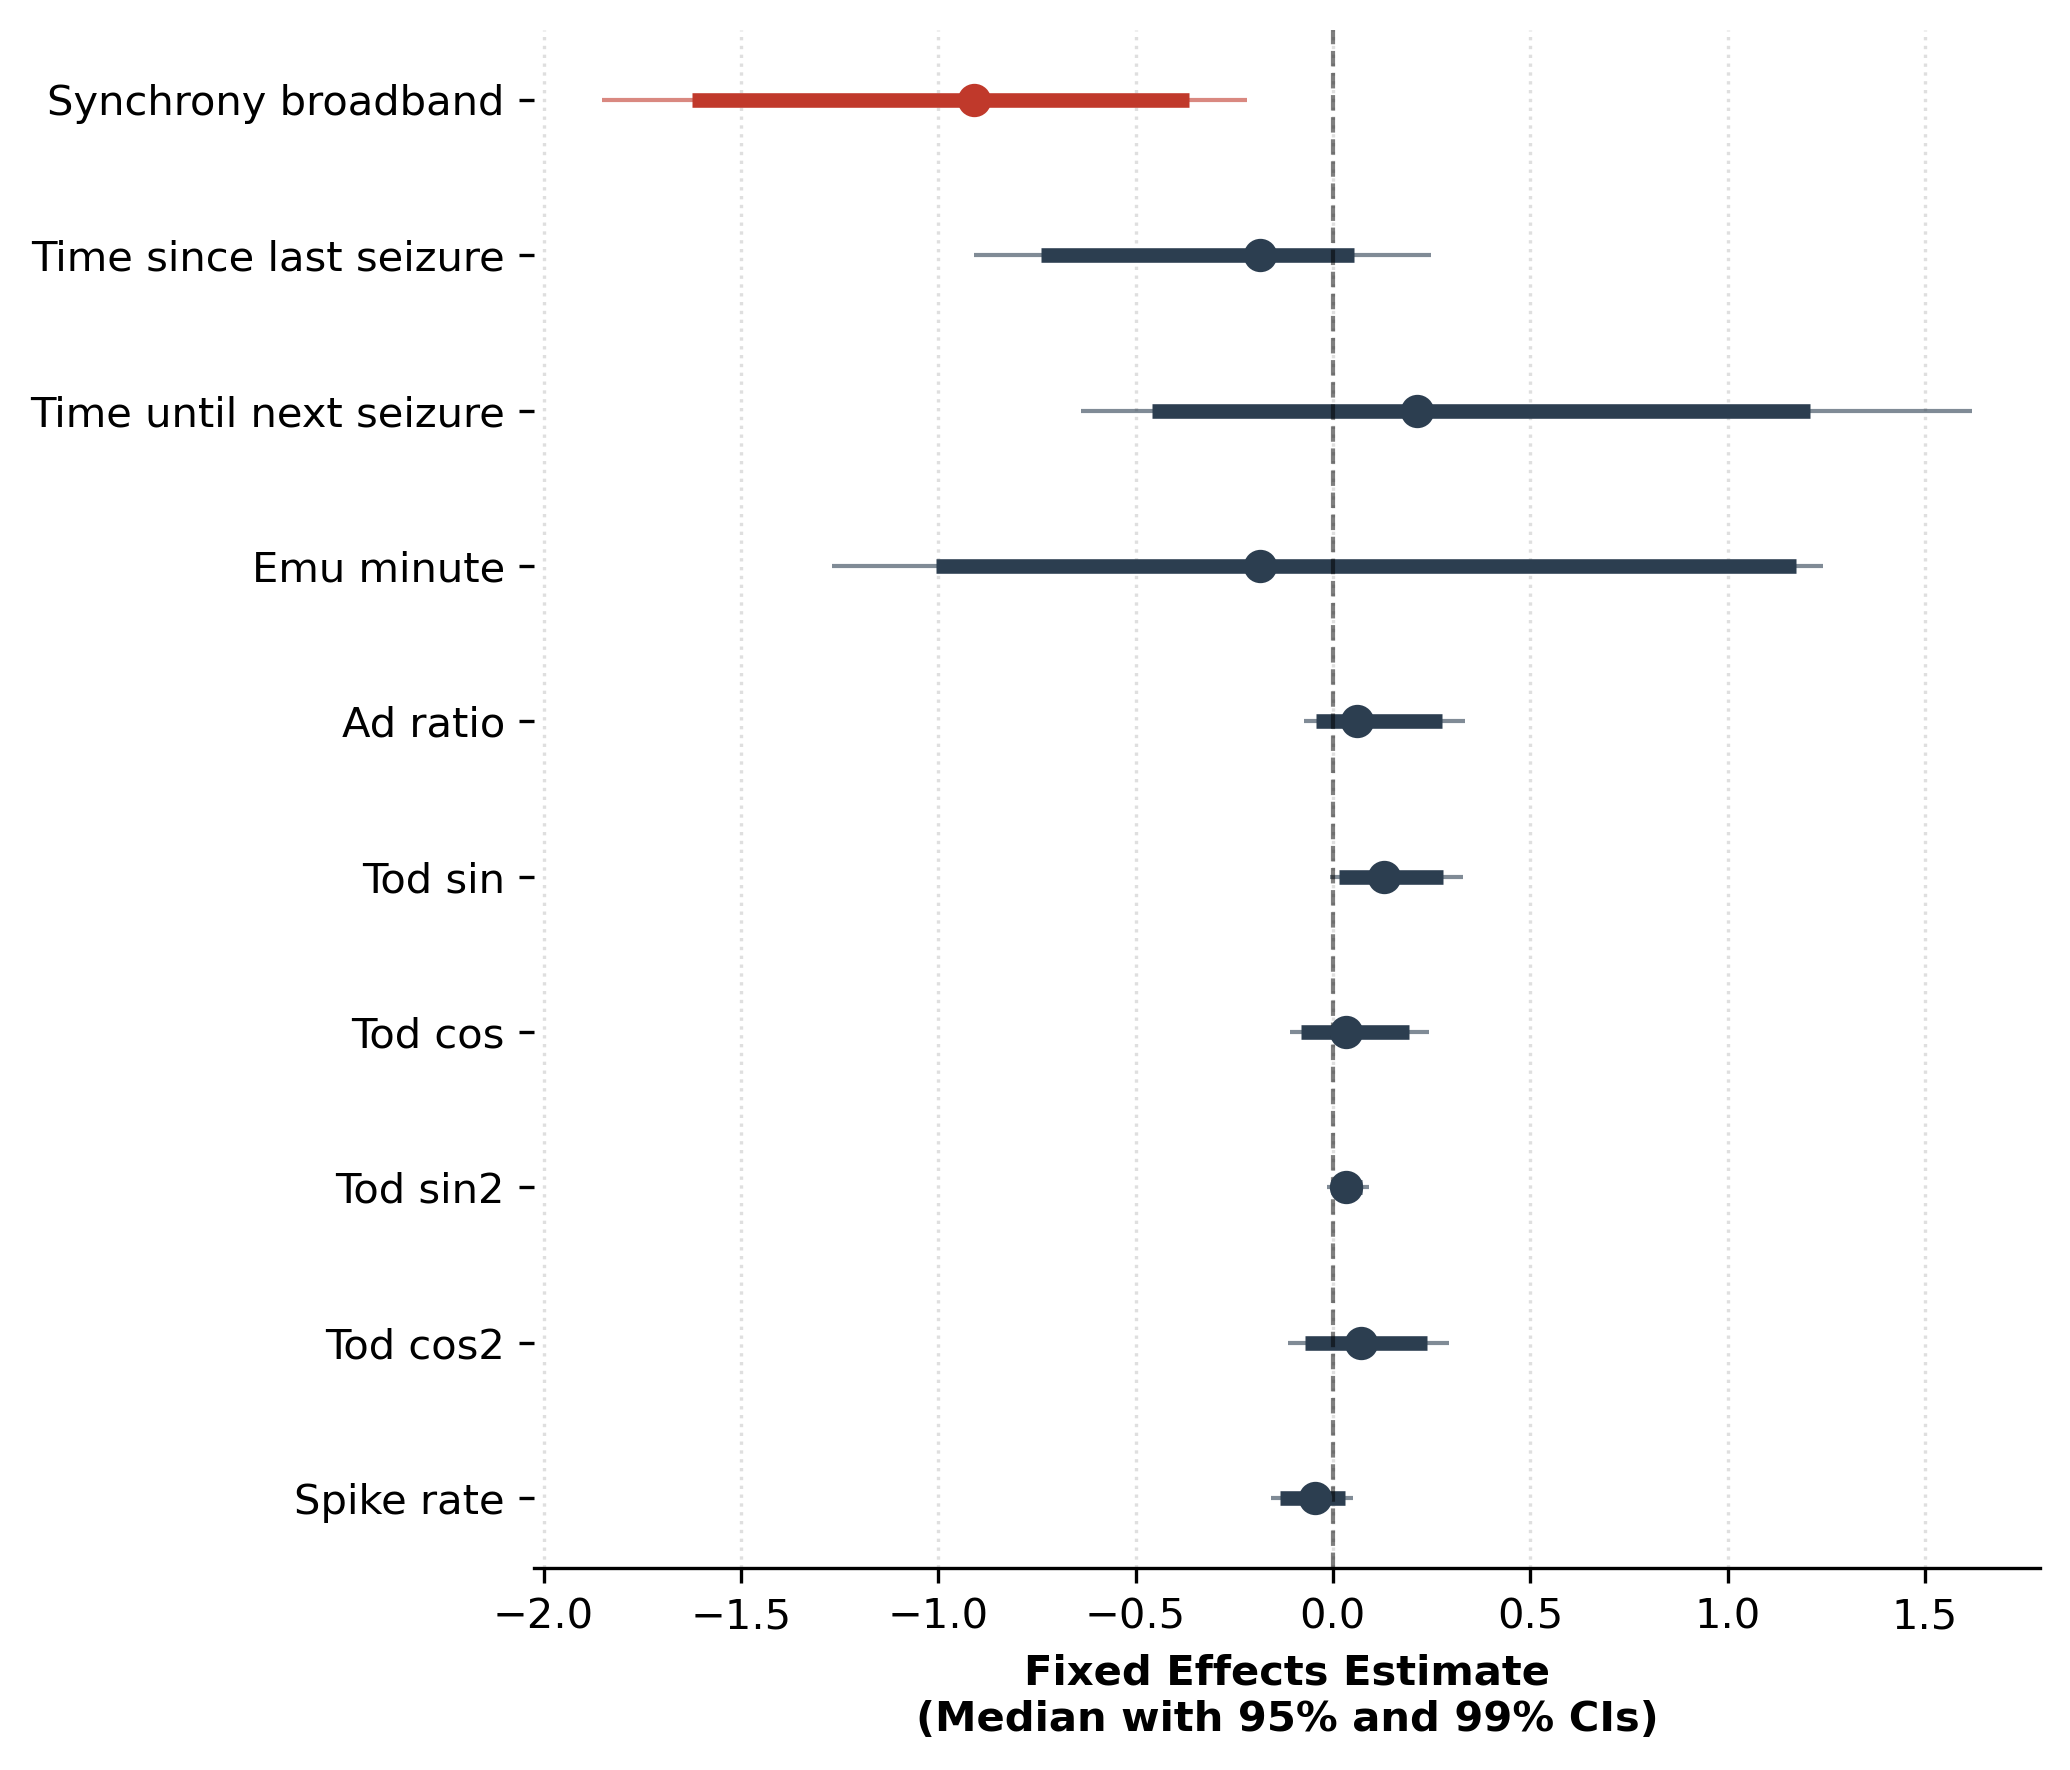

In [18]:
# Leverage the DataFrame loaded from the pickle file
df = bootstrap_summary.copy()

# --- Data Cleaning ---
# Exclude Intercept 
plot_df = df[df['term'] != 'Intercept'].copy()

# Reverse order
plot_df = plot_df.iloc[::-1].reset_index(drop=True)

# Beautify labels
def clean_label(s):
    return s.replace('_', ' ').replace('tod', 'TOD').capitalize()

plot_df['clean_term'] = plot_df['term'].apply(clean_label)

# --- Plotting ---
fig, ax = plt.subplots(figsize=(7, 6), dpi=300)

y_pos = np.arange(len(plot_df))

for i, row in plot_df.iterrows():
    
    is_highlight = row['term'] == 'synchrony_broadband'
    
    main_color = '#2c3e50' if not is_highlight else '#c0392b' 
    
    # 1. Draw 99% CI (Thin Line)
    ax.hlines(y=i, xmin=row['ci99_lower'], xmax=row['ci99_upper'], 
              linewidth=1.0, color=main_color, alpha=0.6)
    
    # 2. Draw 95% CI (Thick Line)
    ax.hlines(y=i, xmin=row['ci95_lower'], xmax=row['ci95_upper'], 
              linewidth=3.5, color=main_color)
    
    # 3. Draw Median (Point)
    ax.plot(row['median'], i, 'o', markersize=7, color=main_color, zorder=3)

# --- Styling ---
ax.axvline(x=0, color='black', linestyle='--', linewidth=1, alpha=0.5)

ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df['clean_term'], fontsize=10)

ax.set_xlabel('Fixed Effects Estimate\n(Median with 95% and 99% CIs)', fontsize=10, fontweight='bold')

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False) 
ax.grid(axis='x', linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()

## Nakagawa & Schielzeth method

Full Model Formula:
 med_sum_no_lorazepam_raw ~ synchrony_broadband + time_since_last_seizure + time_until_next_seizure + emu_minute + ad_ratio + tod_sin + tod_cos + tod_sin2 + tod_cos2 + spike_rate

--- Full Model Performance (Nakagawa) ---
Marginal R² (Fixed Effects only):    0.1938
Conditional R² (Fixed + Random Eff): 0.9071

Starting Leave-One-Out analysis on 10 predictors...

--- Semi-Partial Marginal R² (Unique Variance Explained) ---
                   term  delta_r2  reduced_marginal_r2
    synchrony_broadband   0.14049              0.05333
time_until_next_seizure   0.00988              0.18394
             emu_minute   0.00637              0.18745
               tod_cos2  -0.00038              0.19420
               ad_ratio  -0.00051              0.19433
               tod_sin2  -0.00110              0.19492
             spike_rate  -0.00134              0.19516
                tod_cos  -0.00402              0.19784
                tod_sin  -0.00862              0.20244
time_

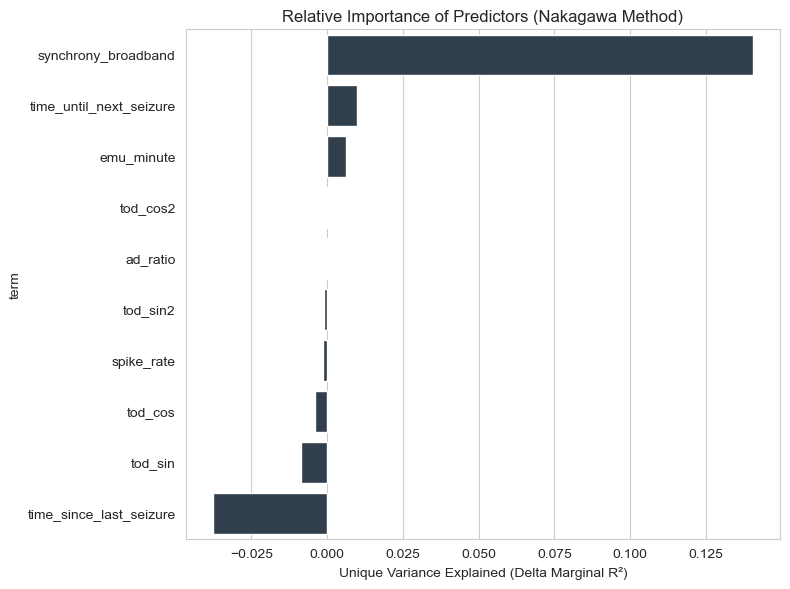

In [14]:
# --- 1. SETUP ---

outcome_var = "med_sum_no_lorazepam_raw"
predictor_vars = [
    "synchrony_broadband",
    "time_since_last_seizure",
    "time_until_next_seizure",
    "emu_minute",
    "ad_ratio",
    "tod_sin",
    "tod_cos",
    "tod_sin2",
    "tod_cos2",
    "spike_rate",
]

# --- 2. DEFINE NAKAGAWA R2 FUNCTION (CORRECTED) ---

def get_nakagawa_r2(model_result):
    """
    Calculates Marginal and Conditional R^2 using the Nakagawa & Schielzeth method.
    Returns dictionary with 'marginal' and 'conditional'.
    """
    
    # A. Variance of Fixed Effects (σ²_f)
    # FIX: Use manual dot product (X @ beta) to avoid patsy/DataFrame errors
    # model.exog is the Design Matrix (X)
    # result.fe_params are the fixed effect coefficients (beta)
    pred_fixed = np.dot(model_result.model.exog, model_result.fe_params)
    var_fixed = np.var(pred_fixed)

    # B. Variance of Random Effects (σ²_r)
    # For a Random Intercept model, this is the first element of the covariance matrix
    # model_result.cov_re is a DataFrame; we take the top-left value
    var_random = model_result.cov_re.iloc[0, 0]

    # C. Variance of Residuals (σ²_ε)
    # In statsmodels MixedLM, this is stored as 'scale'
    var_resid = model_result.scale

    # D. Calculate R2
    total_var = var_fixed + var_random + var_resid
    
    # Marginal R2: Variance explained by Fixed Effects only
    r2_marginal = var_fixed / total_var
    
    # Conditional R2: Variance explained by Fixed + Random Effects
    r2_conditional = (var_fixed + var_random) / total_var

    return {
        "marginal": r2_marginal, 
        "conditional": r2_conditional, 
        "var_fixed": var_fixed,
        "var_random": var_random,
        "var_resid": var_resid
    }

# --- 3. FIT FULL MODEL ---

full_formula = outcome_var + " ~ " + " + ".join(predictor_vars)
print("Full Model Formula:\n", full_formula)

full_model = smf.mixedlm(
    full_formula,
    all_data,
    groups=all_data["patient_hup_id"],
)
full_result = full_model.fit(reml=True) 

# Calculate R2 for full model
full_r2_stats = get_nakagawa_r2(full_result)

print("\n--- Full Model Performance (Nakagawa) ---")
print(f"Marginal R² (Fixed Effects only):    {full_r2_stats['marginal']:.4f}")
print(f"Conditional R² (Fixed + Random Eff): {full_r2_stats['conditional']:.4f}")

# --- 4. LEAVE-ONE-OUT ANALYSIS (Semi-Partial R2) ---

partial_r2_rows = []

print(f"\nStarting Leave-One-Out analysis on {len(predictor_vars)} predictors...")

for var in predictor_vars:
    # Build reduced formula by leaving this predictor out
    reduced_predictors = [v for v in predictor_vars if v != var]
    reduced_formula = outcome_var + " ~ " + " + ".join(reduced_predictors)

    # Fit reduced model
    reduced_model = smf.mixedlm(
        reduced_formula,
        all_data,
        groups=all_data["patient_hup_id"],
    )
    # disp=0 suppresses convergence logs
    reduced_result = reduced_model.fit(reml=True) 

    # Calculate Reduced MARGINAL R^2
    reduced_r2_stats = get_nakagawa_r2(reduced_result)
    r2_reduced_marginal = reduced_r2_stats['marginal']
    
    # The Delta is the unique contribution of this variable to the Fixed Effects
    delta_r2 = full_r2_stats['marginal'] - r2_reduced_marginal 

    partial_r2_rows.append({
        "term": var,
        "full_marginal_r2": full_r2_stats['marginal'],
        "reduced_marginal_r2": r2_reduced_marginal,
        "delta_r2": delta_r2, 
    })

# --- 5. RESULTS & PLOTTING ---

partial_r2_df = pd.DataFrame(partial_r2_rows)
partial_r2_df = partial_r2_df.sort_values("delta_r2", ascending=False)

print("\n--- Semi-Partial Marginal R² (Unique Variance Explained) ---")
print(partial_r2_df[["term", "delta_r2", "reduced_marginal_r2"]].round(5).to_string(index=False))

plt.figure(figsize=(8, 6))
sns.barplot(data=partial_r2_df, x="delta_r2", y="term", color="#2c3e50")
plt.xlabel("Unique Variance Explained (Delta Marginal R²)")
plt.title("Relative Importance of Predictors (Nakagawa Method)")
plt.tight_layout()
plt.show()